In [2]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [3]:
!mkdir -p data
!mv "KDDTrain+.txt" "KDDTest+.txt" data/
!ls data

KDDTest+.txt  KDDTrain+.txt


In [4]:
import pandas as pd
df = pd.read_csv("data/KDDTrain+.txt", header=None)
print(df.shape)   # expect (125973, 43)

(125973, 43)


In [5]:
!pip install -q scikit-learn pandas joblib matplotlib

In [6]:
import pandas as pd

COLUMNS = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty",
]
CATEGORICAL = ["protocol_type", "service", "flag"]

def load_nsl_kdd(path):
    df = pd.read_csv(path, names=COLUMNS)
    df = df.drop(columns=["difficulty"])
    df["target"] = (df["label"] != "normal").astype(int)  # 0 normal, 1 attack
    return df

def split_xy(df):
    X = df.drop(columns=["label", "target"])
    y = df["target"]
    return X, y

In [7]:
train = load_nsl_kdd("data/KDDTrain+.txt")
test = load_nsl_kdd("data/KDDTest+.txt")
print(train.shape, test.shape)
print(train["target"].value_counts())
print(train["label"].value_counts().head(10))

(125973, 43) (22544, 43)
target
0    67343
1    58630
Name: count, dtype: int64
label
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(X):
    numeric = [c for c in X.columns if c not in CATEGORICAL]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ("num", StandardScaler(), numeric),
    ])

X_train, y_train = split_xy(train)
X_test, y_test = split_xy(test)

rf = Pipeline([
    ("prep", build_preprocessor(X_train)),
    ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
]).fit(X_train, y_train)

iso = Pipeline([
    ("prep", build_preprocessor(X_train)),
    ("clf", IsolationForest(n_estimators=100, contamination=0.1, random_state=42)),
]).fit(X_train[y_train == 0])

print("Models trained")

Models trained


--- random_forest ---
Accuracy : 0.7787
Precision: 0.9689
Recall   : 0.6314
F1       : 0.7646


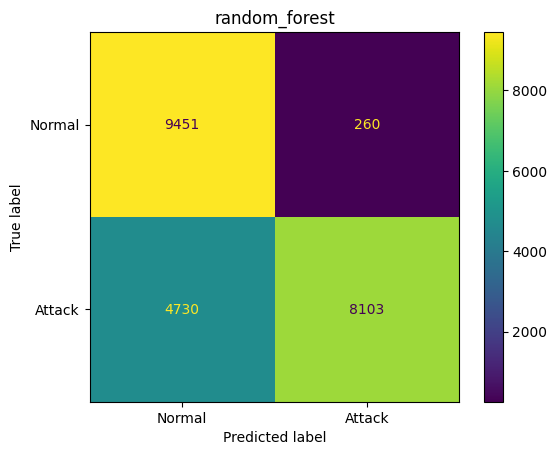

--- isolation_forest ---
Accuracy : 0.8022
Precision: 0.9274
Recall   : 0.7079
F1       : 0.8029


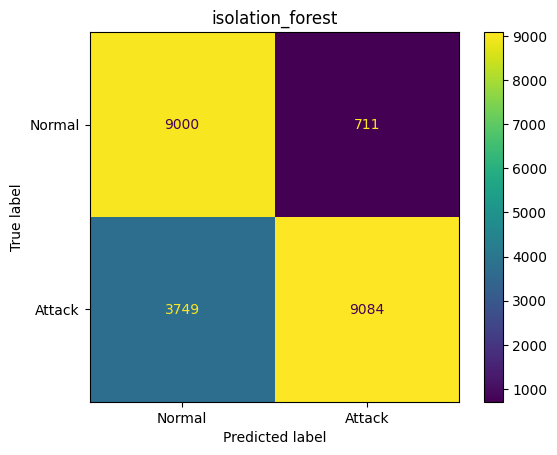

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

def report(name, y_true, y_pred):
    print(f"--- {name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1       :", round(f1_score(y_true, y_pred), 4))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot()
    plt.title(name)
    plt.savefig(f"cm_{name}.png")
    plt.show()

report("random_forest", y_test, rf.predict(X_test))
iso_pred = (iso.predict(X_test) == -1).astype(int)
report("isolation_forest", y_test, iso_pred)

In [10]:
import numpy as np
proba = rf.predict_proba(X_test)[:, 1]
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (proba >= t).astype(int)
    print(t, "acc", round(accuracy_score(y_test, pred), 4),
          "prec", round(precision_score(y_test, pred), 4),
          "rec", round(recall_score(y_test, pred), 4),
          "f1", round(f1_score(y_test, pred), 4))

0.5 acc 0.7796 prec 0.969 rec 0.6331 f1 0.7659
0.4 acc 0.8045 prec 0.9695 rec 0.6779 f1 0.7979
0.3 acc 0.8283 prec 0.9678 rec 0.7224 f1 0.8273
0.2 acc 0.8447 prec 0.9352 rec 0.7813 f1 0.8514
0.1 acc 0.889 prec 0.9225 rec 0.8788 f1 0.9002


--- hybrid_rf_or_iso ---
Accuracy : 0.8358
Precision: 0.9287
Recall   : 0.7707
F1       : 0.8423


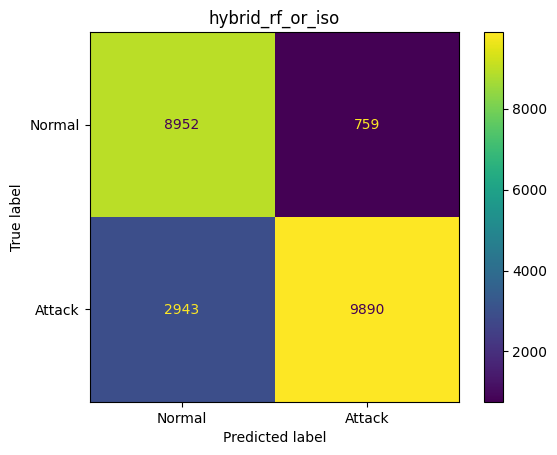

In [11]:
rf_pred = rf.predict(X_test)
hybrid = ((rf_pred == 1) | (iso_pred == 1)).astype(int)
report("hybrid_rf_or_iso", y_test, hybrid)

In [12]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

def tree_prep():
    return ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)],
        remainder="passthrough")

candidates = {
    "extra_trees": ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    "hist_gb": HistGradientBoostingClassifier(random_state=42),
    "rf_depth12": RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
}
for name, m in candidates.items():
    p = Pipeline([("prep", tree_prep()), ("clf", m)]).fit(X_train, y_train)
    pred = p.predict(X_test)
    print(name, "acc", round(accuracy_score(y_test, pred), 4),
          "prec", round(precision_score(y_test, pred), 4),
          "rec", round(recall_score(y_test, pred), 4))

extra_trees acc 0.7794 prec 0.9664 rec 0.6345
hist_gb acc 0.8113 prec 0.9687 rec 0.6907
rf_depth12 acc 0.7761 prec 0.968 rec 0.6274


In [13]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

rf2 = Pipeline([
    ("prep", build_preprocessor(X_tr)),
    ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
]).fit(X_tr, y_tr)

val_proba = rf2.predict_proba(X_val)[:, 1]
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    p = (val_proba >= t).astype(int)
    print(t, "rec", round(recall_score(y_val, p), 4), "prec", round(precision_score(y_val, p), 4))

0.5 rec 0.9985 prec 0.9995
0.4 rec 0.9992 prec 0.9992
0.3 rec 0.9994 prec 0.9978
0.2 rec 0.9997 prec 0.9964
0.1 rec 0.9997 prec 0.9917


In [14]:
def _label(score):
    if score >= 0.5:
        return "Malicious"
    if score >= 0.2:
        return "Suspicious"
    return "Normal"

In [15]:
import joblib
from google.colab import files
joblib.dump(rf, "rf_model.pkl")
files.download("rf_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from sklearn.metrics import roc_auc_score
proba = rf.predict_proba(X_test)[:, 1]
print("RF ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
iso_score = -iso.score_samples(X_test)
print("ISO ROC-AUC:", round(roc_auc_score(y_test, iso_score), 4))

RF ROC-AUC: 0.9598
ISO ROC-AUC: 0.9365


--- hybrid_3level ---
Accuracy : 0.8563
Precision: 0.923
Recall   : 0.8156
F1       : 0.866


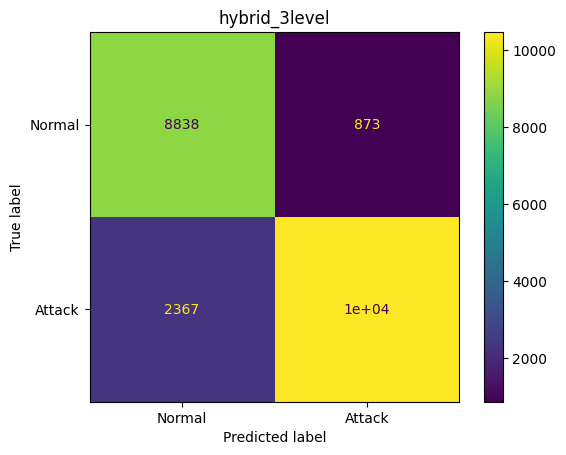

Normal        11205
Malicious      8385
Suspicious     2954
Name: count, dtype: int64


In [18]:
import numpy as np
rf_p = rf.predict_proba(X_test)[:, 1]
anom = (iso.predict(X_test) == -1)
label = np.where(rf_p >= 0.5, "Malicious",
         np.where((rf_p >= 0.2) | anom, "Suspicious", "Normal"))
pred = (label != "Normal").astype(int)   # Suspicious + Malicious = alert
report("hybrid_3level", y_test, pred)
print(pd.Series(label).value_counts())

In [19]:
sus = (label == "Suspicious")
print("Suspicious mein attacks:", int(y_test[sus].sum()), "/", int(sus.sum()))
mal = (label == "Malicious")
print("Malicious mein attacks :", int(y_test[mal].sum()), "/", int(mal.sum()))

Suspicious mein attacks: 2341 / 2954
Malicious mein attacks : 8125 / 8385


In [21]:
import joblib, sklearn
from google.colab import files

joblib.dump(rf, "rf_model.pkl")
joblib.dump(iso, "iso_model.pkl")
print("sklearn version:", sklearn.__version__)

files.download("rf_model.pkl")
files.download("iso_model.pkl")
files.download("cm_random_forest.png")
files.download("cm_isolation_forest.png")
files.download("cm_hybrid_3level.png")

sklearn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>